# 01 · Explore the LowRes-EffTransNAS Search Space

This notebook inspects the discrete search space, samples random architectures,
estimates parameter counts / FLOPs, and visualises the design space.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

from nas.search_space import SearchSpace, Architecture

space = SearchSpace()
print('Depth choices :', space.DEPTH_CHOICES)
print('Dim choices   :', space.DIM_CHOICES)
print('Head choices  :', space.HEAD_CHOICES)
print('Ratio choices :', space.RATIO_CHOICES)
print('Attn choices  :', space.ATTN_CHOICES)

Depth choices : [4, 6, 8, 10, 12]
Dim choices   : [128, 192, 256, 320, 384, 512, 768]
Head choices  : [2, 4, 6, 8, 12]
Ratio choices : [1.0, 1.5, 2.0, 2.5, 3.0, 4.0]
Attn choices  : ['softmax', 'linear', 'sparse-local']


In [2]:
# Sample 500 random architectures and estimate cost
samples = [space.sample() for _ in range(500)]
params = [space.estimate_params(a) / 1e6 for a in samples]
flops  = [space.estimate_flops(a) / 1e9 for a in samples]

print(f'Params  mean={np.mean(params):.1f}M  min={np.min(params):.1f}M  max={np.max(params):.1f}M')
print(f'FLOPs   mean={np.mean(flops):.2f}G  min={np.min(flops):.2f}G  max={np.max(flops):.2f}G')

Params  mean=24.9M  min=4.6M  max=109.9M
FLOPs   mean=1.18G  min=0.02G  max=9.06G


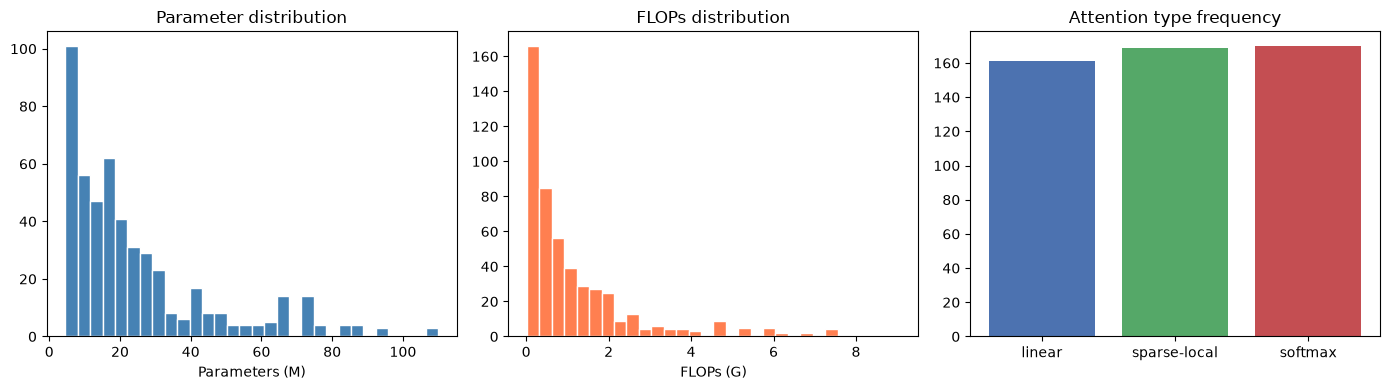

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(params, bins=30, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Parameters (M)')
axes[0].set_title('Parameter distribution')

axes[1].hist(flops, bins=30, color='coral', edgecolor='white')
axes[1].set_xlabel('FLOPs (G)')
axes[1].set_title('FLOPs distribution')

attn_counts = Counter(a.attn_type for a in samples)
axes[2].bar(attn_counts.keys(), attn_counts.values(), color=['#4c72b0','#55a868','#c44e52'])
axes[2].set_title('Attention type frequency')

plt.tight_layout()
plt.show()

In [4]:
# Mutation example
parent = space.sample()
print('Parent :', parent)
child = space.mutate(parent, prob=0.3)
print('Child  :', child)

Parent : Architecture(depth=10, dim=256, heads=8, ratio=2.0, attn_type='linear', layer_attn=None, layer_dim=None, layer_heads=None, layer_ratio=None)
Child  : Architecture(depth=4, dim=256, heads=8, ratio=2.0, attn_type='linear', layer_attn=None, layer_dim=None, layer_heads=None, layer_ratio=None)


## Take-away
The search space spans roughly **4 M – 90 M** parameters and covers three attention operators.
This motivates the progressive-shrinkage super-network and multi-objective selection used in the paper.